In [1]:
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu118


Looking in indexes: https://download.pytorch.org/whl/cu118
Note: you may need to restart the kernel to use updated packages.


In [11]:
!pip install transformers optuna pandas numpy scikit-learn requests tqdm matplotlib seaborn

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import pandas as pd
import numpy as np
import requests
import csv
from io import StringIO
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import optuna
from optuna.trial import TrialState
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check for GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


/home/matheus/Documentos/Sync/Artigo/DistilBERT-X-CharLSTM/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda


/opt/amdgpu/share/libdrm/amdgpu.ids: No such file or directory


In [7]:
import numpy as np
import pandas as pd
df = pd.read_csv('domain_dataset.csv')

# Length of every domain string
lengths = df["domain"].str.len()

print(f"Number of domains: {len(lengths)}")
print(f"Minimum length: {lengths.min()}")
print(f"Mean length: {lengths.mean():.2f}")
print(f"Median length: {lengths.median()}")
print(f"95th percentile: {lengths.quantile(0.95):.0f}")
print(f"99th percentile: {lengths.quantile(0.99):.0f}")
print(f"Maximum length: {lengths.max()}")
print(f"Number of domains with more than 32 tokens: {len([x for x in lengths if x <= 32])}")

Number of domains: 1242174
Minimum length: 4
Mean length: 15.48
Median length: 15.0
95th percentile: 25
99th percentile: 34
Maximum length: 149
Number of domains with more than 32 tokens: 1226268


In [16]:
class CharacterTokenizer:
    """
    Character-level tokenizer for domain names
    Based on best practices from Yu et al. (2018)
    """
    def __init__(self, max_length=32):
        self.max_length = max_length
        self.vocab_size = 128  # ASCII characters

    def encode(self, domain):
        """
        Encode domain name as sequence of ASCII values
        """
        domain = domain.lower()

        encoded = [ord(c) if ord(c) < 128 else 0 for c in domain]

        if len(encoded) < self.max_length:
            encoded = [0] * (self.max_length - len(encoded)) + encoded
        else:
            encoded = encoded[:self.max_length]

        return encoded

    def batch_encode(self, domains):
        """
        Encode a batch of domains
        """
        return [self.encode(domain) for domain in domains]

tokenizer = CharacterTokenizer(max_length=32)

sample_domain = "google.com"
encoded = tokenizer.encode(sample_domain)
print(f"Sample domain: {sample_domain}")
print(f"Encoded (first 10): {encoded[-10:]}")
print(f"Encoded length: {len(encoded)}")

Sample domain: google.com
Encoded (first 10): [103, 111, 111, 103, 108, 101, 46, 99, 111, 109]
Encoded length: 32


In [17]:
class DomainDataset(Dataset):
    """
    PyTorch Dataset for domain classification
    """
    def __init__(self, domains, labels, tokenizer):
        self.domains = domains
        self.labels = labels
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.domains)

    def __getitem__(self, idx):
        domain = self.domains[idx]
        label = self.labels[idx]

        # Encode domain
        encoded = self.tokenizer.encode(domain)

        return {
            'input': torch.tensor(encoded, dtype=torch.long),
            'label': torch.tensor(label, dtype=torch.float)
        }

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=42, stratify=test_df['label'])

print(f"Train size: {len(train_df)}")
print(f"Validation size: {len(val_df)}")
print(f"Test size: {len(test_df)}")

train_dataset = DomainDataset(train_df['domain'].tolist(), train_df['label'].tolist(), tokenizer)
val_dataset = DomainDataset(val_df['domain'].tolist(), val_df['label'].tolist(), tokenizer)
test_dataset = DomainDataset(test_df['domain'].tolist(), test_df['label'].tolist(), tokenizer)

Train size: 993739
Validation size: 124217
Test size: 124218


In [12]:
class CharCNN(nn.Module):
    """
    Character-level CNN for domain classification
    Based on NYU model (Zhang et al., 2015) adapted for short strings
    """
    def __init__(self, vocab_size=128, embedding_dim=128, max_length=64,
                 num_filters=128, dropout_rate=0.5):
        super(CharCNN, self).__init__()

        # Embedding layer
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        # Convolutional layers (stacked)
        self.conv1 = nn.Conv1d(embedding_dim, num_filters, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(num_filters, num_filters, kernel_size=2, padding=1)

        # Pooling
        self.pool = nn.MaxPool1d(2)

        # Calculate size after convolutions and pooling
        conv_output_size = num_filters * (max_length // 4)

        # Fully connected layers
        self.fc1 = nn.Linear(conv_output_size, 64)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        # Embedding: (batch, seq_len) -> (batch, seq_len, embedding_dim)
        x = self.embedding(x)

        # Transpose for conv1d: (batch, embedding_dim, seq_len)
        x = x.transpose(1, 2)

        # Conv1 + activation + pool
        x = self.pool(F.relu(self.conv1(x)))

        # Conv2 + activation + pool
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully connected layers
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

class CharLSTM(nn.Module):
    """
    Character-level LSTM for domain classification
    Based on Endgame model (Woodbridge et al., 2016)
    """
    def __init__(self, vocab_size=128, embedding_dim=128, hidden_dim=128, dropout_rate=0.5):
        super(CharLSTM, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        # Embedding
        x = self.embedding(x)

        # LSTM
        lstm_out, (hidden, cell) = self.lstm(x)

        # Use last hidden state
        x = hidden[-1]

        # Dropout and output
        x = self.dropout(x)
        x = self.fc(x)

        return x

class CharBiLSTM(nn.Module):
    """
    Bidirectional LSTM for domain classification
    Based on CMU model (Dhingra et al., 2016)
    """
    def __init__(self, vocab_size=128, embedding_dim=128, hidden_dim=64, dropout_rate=0.5):
        super(CharBiLSTM, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(hidden_dim * 2, 1)  # *2 for bidirectional

    def forward(self, x):
        x = self.embedding(x)
        lstm_out, (hidden, cell) = self.bilstm(x)

        # Concatenate forward and backward hidden states
        x = torch.cat((hidden[-2], hidden[-1]), dim=1)

        x = self.dropout(x)
        x = self.fc(x)

        return x

class CharCNNLSTM(nn.Module):
    """
    Hybrid CNN-LSTM architecture
    Based on MIT model (Vosoughi et al., 2016)
    """
    def __init__(self, vocab_size=128, embedding_dim=128, num_filters=128,
                 lstm_hidden=64, dropout_rate=0.5):
        super(CharCNNLSTM, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.conv = nn.Conv1d(embedding_dim, num_filters, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2)
        self.lstm = nn.LSTM(num_filters, lstm_hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout_rate)
        self.fc = nn.Linear(lstm_hidden, 1)

    def forward(self, x):
        # Embedding
        x = self.embedding(x)
        x = x.transpose(1, 2)

        # CNN + pooling
        x = self.pool(F.relu(self.conv(x)))

        # Transpose back for LSTM
        x = x.transpose(1, 2)

        # LSTM
        lstm_out, (hidden, cell) = self.lstm(x)
        x = hidden[-1]

        # Output
        x = self.dropout(x)
        x = self.fc(x)

        return x

# Test model instantiation
model = CharCNN().to(device)
print(f"CharCNN parameters: {sum(p.numel() for p in model.parameters()):,}")

model = CharLSTM().to(device)
print(f"CharLSTM parameters: {sum(p.numel() for p in model.parameters()):,}")

model = CharBiLSTM().to(device)
print(f"CharBiLSTM parameters: {sum(p.numel() for p in model.parameters()):,}")

model = CharCNNLSTM().to(device)
print(f"CharCNNLSTM parameters: {sum(p.numel() for p in model.parameters()):,}")

CharCNN parameters: 229,761
CharLSTM parameters: 148,609
CharBiLSTM parameters: 115,841
CharCNNLSTM parameters: 115,393


In [13]:
def train_epoch(model, dataloader, criterion, optimizer, device):
    """Train for one epoch"""
    model.train()
    total_loss = 0

    for batch in tqdm(dataloader, desc="Training", leave=False):
        inputs = batch['input'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()
        outputs = model(inputs).squeeze()
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(dataloader)

def evaluate(model, dataloader, criterion, device):
    """Evaluate model"""
    model.eval()
    total_loss = 0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch in dataloader:
            inputs = batch['input'].to(device)
            labels = batch['label'].to(device)

            outputs = model(inputs).squeeze()
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)

    return {
        'loss': avg_loss,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc': auc
    }

def train_model(model, train_loader, val_loader, epochs=10, lr=0.001, patience=2):
    """Complete training loop"""
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_f1 = 0
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}

    for epoch in range(epochs):
        train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
        val_metrics = evaluate(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_metrics['loss'])
        history['val_f1'].append(val_metrics['f1'])

        print(f"Epoch {epoch+1}/{epochs}")
        print(f"  Train Loss: {train_loss:.4f}")
        print(f"  Val Loss: {val_metrics['loss']:.4f}, F1: {val_metrics['f1']:.4f}, AUC: {val_metrics['auc']:.4f}")

        # Save best model
        if val_metrics['f1'] > best_val_f1:
            best_val_f1 = val_metrics['f1']
            patience_counter = 0
            torch.save(model.state_dict(), 'best_model.pt')
        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

    return history

In [14]:
class CharCNN(nn.Module):
    def __init__(self, vocab_size=128, embedding_dim=128, max_length=64,
                 num_filters=128, dropout_rate=0.5):
        super(CharCNN, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.conv1 = nn.Conv1d(embedding_dim, num_filters, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(num_filters, num_filters, kernel_size=2, padding=1)
        self.pool = nn.MaxPool1d(2)
        self.dropout = nn.Dropout(dropout_rate)

        # Dynamically compute flatten size to avoid shape errors
        with torch.no_grad():
            tmp = torch.zeros(1, max_length, dtype=torch.long)
            tmp = self.embedding(tmp).transpose(1, 2)           # (batch, embedding_dim, seq_len)
            tmp = self.pool(F.relu(self.conv1(tmp)))             # after conv1 + pool
            tmp = self.pool(F.relu(self.conv2(tmp)))             # after conv2 + pool
            flat_size = tmp.view(1, -1).size(1)

        self.fc1 = nn.Linear(flat_size, 64)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.embedding(x)
        x = x.transpose(1, 2)
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

class CharLSTM(nn.Module):
    def __init__(self, vocab_size=128, embedding_dim=128, hidden_dim=128, max_length=64, dropout_rate=0.5):
        super(CharLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout_rate)
        # Dynamic sizing for fc
        with torch.no_grad():
            tmp = torch.zeros(1, max_length, dtype=torch.long)
            tmp = self.embedding(tmp)
            _, (hidden, _) = self.lstm(tmp)
            out_size = hidden[-1].shape[1]
        self.fc = nn.Linear(out_size, 1)
    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.lstm(x)
        x = hidden[-1]
        x = self.dropout(x)
        x = self.fc(x)
        return x

class CharBiLSTM(nn.Module):
    def __init__(self, vocab_size=128, embedding_dim=128, hidden_dim=64, max_length=64, dropout_rate=0.5):
        super(CharBiLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.bilstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout_rate)
        # Dynamic sizing for fc
        with torch.no_grad():
            tmp = torch.zeros(1, max_length, dtype=torch.long)
            tmp = self.embedding(tmp)
            _, (hidden, _) = self.bilstm(tmp)
            # hidden: (num_layers * num_directions, batch, hidden_dim)
            # Use final hidden state from both directions
            out_size = torch.cat((hidden[-2], hidden[-1]), dim=1).shape[1]
        self.fc = nn.Linear(out_size, 1)
    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.bilstm(x)
        x = torch.cat((hidden[-2], hidden[-1]), dim=1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

class CharCNNLSTM(nn.Module):
    def __init__(self, vocab_size=128, embedding_dim=128, num_filters=128, lstm_hidden=64,
                 max_length=64, dropout_rate=0.5):
        super(CharCNNLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.conv = nn.Conv1d(embedding_dim, num_filters, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2)
        self.lstm = nn.LSTM(num_filters, lstm_hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout_rate)
        # Dynamic sizing for fc
        with torch.no_grad():
            tmp = torch.zeros(1, max_length, dtype=torch.long)
            tmp = self.embedding(tmp).transpose(1, 2)
            tmp = self.pool(F.relu(self.conv(tmp)))
            tmp = tmp.transpose(1, 2)
            _, (hidden, _) = self.lstm(tmp)
            out_size = hidden[-1].shape[1]
        self.fc = nn.Linear(out_size, 1)
    def forward(self, x):
        x = self.embedding(x)
        x = x.transpose(1, 2)
        x = self.pool(F.relu(self.conv(x)))
        x = x.transpose(1, 2)
        _, (hidden, _) = self.lstm(x)
        x = hidden[-1]
        x = self.dropout(x)
        x = self.fc(x)
        return x

In [15]:
def objective(trial, model_type='CharCNN'):
    """
    Optuna objective function for hyperparameter optimization
    """
    # Suggest hyperparameters
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
    lr = trial.suggest_loguniform('lr', 1e-4, 1e-2)
    dropout_rate = trial.suggest_uniform('dropout_rate', 0.3, 0.7)
    embedding_dim = trial.suggest_categorical('embedding_dim', [64, 128, 256])

    # Model-specific hyperparameters
    if model_type == 'CharCNN':
        num_filters = trial.suggest_categorical('num_filters', [64, 128, 256])
        model = CharCNN(embedding_dim=embedding_dim, num_filters=num_filters,
                       dropout_rate=dropout_rate).to(device)
    elif model_type == 'CharLSTM':
        hidden_dim = trial.suggest_categorical('hidden_dim', [64, 128, 256])
        model = CharLSTM(embedding_dim=embedding_dim, hidden_dim=hidden_dim,
                        dropout_rate=dropout_rate).to(device)
    elif model_type == 'CharBiLSTM':
        hidden_dim = trial.suggest_categorical('hidden_dim', [32, 64, 128])
        model = CharBiLSTM(embedding_dim=embedding_dim, hidden_dim=hidden_dim,
                          dropout_rate=dropout_rate).to(device)
    elif model_type == 'CharCNNLSTM':
        num_filters = trial.suggest_categorical('num_filters', [64, 128, 256])
        lstm_hidden = trial.suggest_categorical('lstm_hidden', [32, 64, 128])
        model = CharCNNLSTM(embedding_dim=embedding_dim, num_filters=num_filters,
                           lstm_hidden=lstm_hidden, dropout_rate=dropout_rate).to(device)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)

    # Training setup
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Train for a few epochs
    num_epochs = 5  # Reduced for faster optimization

    for epoch in range(num_epochs):
        # Training
        model.train()
        for batch in train_loader:
            inputs = batch['input'].to(device)
            labels = batch['label'].to(device)

            optimizer.zero_grad()
            outputs = model(inputs).squeeze()
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # Validation
        val_metrics = evaluate(model, val_loader, criterion, device)

        # Report intermediate value for pruning
        trial.report(val_metrics['f1'], epoch)

        # Handle pruning
        if trial.should_prune():
            raise optuna.TrialPruned()

    return val_metrics['f1']

# Run optimization for each model type
def optimize_model(model_type, n_trials=20):
    """
    Run Optuna optimization for a specific model
    """
    print(f"\n{'='*60}")
    print(f"Optimizing {model_type}")
    print(f"{'='*60}")

    study = optuna.create_study(
        direction='maximize',
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2)
    )

    study.optimize(lambda trial: objective(trial, model_type), n_trials=n_trials)

    print(f"\nBest trial for {model_type}:")
    print(f"  F1 Score: {study.best_trial.value:.4f}")
    print(f"  Params: {study.best_trial.params}")

    return study

# Optimize each model architecture
studies = {}
#model_types = ['CharCNN', 'CharLSTM', 'CharBiLSTM', 'CharCNNLSTM']

# removed the other models for a test. 
# If you want to reproduce the comparison between all models, 
# change to the list from the line above
model_types = ['CharLSTM']

for model_type in model_types:
    studies[model_type] = optimize_model(model_type, n_trials=20)

[I 2026-09-15 20:37:07,327] A new study created in memory with name: no-name-5b938afe-b6f2-4ba4-afa1-41133d91d9aa
[W 2026-09-15 20:37:07,352] Trial 0 failed with parameters: {'batch_size': 64, 'lr': 0.0013534125863619306, 'dropout_rate': 0.4865135268341572, 'embedding_dim': 256, 'hidden_dim': 128} because of the following error: NameError("name 'train_dataset' is not defined").
Traceback (most recent call last):
  File "/home/matheus/Documentos/Sync/Artigo/DistilBERT-X-CharLSTM/.venv/lib/python3.14/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_137256/1927193110.py", line 80, in <lambda>
    study.optimize(lambda trial: objective(trial, model_type), n_trials=n_trials)
                                 ~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_137256/1927193110.py", line 31, in objective
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
                              ^^^^^


Optimizing CharLSTM


NameError: name 'train_dataset' is not defined

Best trial for CharLSTM:
  F1 Score: 0.8147
  Params: {'batch_size': 32, 'lr': 0.0002404974802676177, 'dropout_rate': 0.3910487002586611, 'embedding_dim': 64, 'hidden_dim': 256}
  
Found in 320 minutes

In [ ]:


def train_best_model(best_params, model_type):
    """Train the best model with optimal hyperparameters"""

    # Extract hyperparameters
    batch_size = best_params['batch_size']
    lr = best_params['lr']
    dropout_rate = best_params['dropout_rate']
    embedding_dim = best_params['embedding_dim']

    # Create model with best hyperparameters
    if model_type == 'CharCNN':
        model = CharCNN(
            embedding_dim=embedding_dim,
            num_filters=best_params['num_filters'],
            dropout_rate=dropout_rate
        ).to(device)
    elif model_type == 'CharLSTM':
        model = CharLSTM(
            embedding_dim=embedding_dim,
            hidden_dim=best_params['hidden_dim'],
            dropout_rate=dropout_rate
        ).to(device)
    elif model_type == 'CharBiLSTM':
        model = CharBiLSTM(
            embedding_dim=embedding_dim,
            hidden_dim=best_params['hidden_dim'],
            dropout_rate=dropout_rate
        ).to(device)
    elif model_type == 'CharCNNLSTM':
        model = CharCNNLSTM(
            embedding_dim=embedding_dim,
            num_filters=best_params['num_filters'],
            lstm_hidden=best_params['lstm_hidden'],
            dropout_rate=dropout_rate
        ).to(device)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)

    # Train model
    print(f"\nTraining final {model_type} model...")
    history = train_model(model, train_loader, val_loader, epochs=15, lr=lr)

    # Load best model
    model.load_state_dict(torch.load('best_model.pt'))

    # Final evaluation on test set
    criterion = nn.BCEWithLogitsLoss()
    test_metrics = evaluate(model, test_loader, criterion, device)

    print(f"\nFinal Test Results for {model_type}:")
    print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
    print(f"  Precision: {test_metrics['precision']:.4f}")
    print(f"  Recall: {test_metrics['recall']:.4f}")
    print(f"  F1 Score: {test_metrics['f1']:.4f}")
    print(f"  AUC-ROC: {test_metrics['auc']:.4f}")

    return model, history, test_metrics

# Find the best model across all architectures
best_model_type = max(studies.keys(), key=lambda k: studies[k].best_trial.value)
print(f"\nBest overall model: {best_model_type}")
print(f"Best F1 Score: {studies[best_model_type].best_trial.value:.4f}")

# Train the best model
best_model, history, test_metrics = train_best_model(
    studies[best_model_type].best_trial.params,
    best_model_type
)

# Save final model
torch.save(best_model.state_dict(), f'final_{best_model_type}_model.pt')


Best overall model: CharLSTM
Best F1 Score: 0.8147

Training final CharLSTM model...


Epoch 1/15
  Train Loss: 0.4244
  Val Loss: 0.4039, F1: 0.7904, AUC: 0.8910


Epoch 2/15
  Train Loss: 0.3895
  Val Loss: 0.3805, F1: 0.8004, AUC: 0.9013


Epoch 3/15
  Train Loss: 0.3714
  Val Loss: 0.3736, F1: 0.8105, AUC: 0.9070


Epoch 4/15
  Train Loss: 0.3576
  Val Loss: 0.3653, F1: 0.8123, AUC: 0.9099


...

Epoch 11/15
  Train Loss: 0.2847
  Val Loss: 0.3869, F1: 0.8170, AUC: 0.9103


Epoch 12/15
  Train Loss: 0.2755
  Val Loss: 0.3861, F1: 0.8157, AUC: 0.9094


Epoch 13/15
  Train Loss: 0.2676
  Val Loss: 0.4040, F1: 0.8149, AUC: 0.9082


Epoch 14/15
  Train Loss: 0.2599
  Val Loss: 0.4092, F1: 0.8135, AUC: 0.9064


Epoch 15/15
  Train Loss: 0.2524
  Val Loss: 0.4197, F1: 0.8136, AUC: 0.9055

Final Test Results for CharLSTM:
  Accuracy: 0.8229
  Precision: 0.8467
  Recall: 0.7886
  F1 Score: 0.8166
  AUC-ROC: 0.9103


## Training CharLSTM specifically and calculating metrics

In [18]:
# Directly train the CharLSTM model specifically
def train_charlstm(best_params):
    """Train the best model with optimal hyperparameters"""

    # Extract hyperparameters
    batch_size = best_params['batch_size']
    lr = best_params['lr']
    dropout_rate = best_params['dropout_rate']
    embedding_dim = best_params['embedding_dim']

    # Create model with best hyperparameters
    model = CharLSTM(
        embedding_dim=embedding_dim,
        hidden_dim=best_params['hidden_dim'],
        dropout_rate=dropout_rate
    ).to(device)

    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)
    test_loader = DataLoader(test_dataset, batch_size=batch_size)

    # Train model
    print(f"\nTraining final CharLSTM model...")
    history = train_model(model, train_loader, val_loader, epochs=15, lr=lr, patience=2)

    # Load best model
   # model.load_state_dict(torch.load('best_model.pt'))

    # Final evaluation on test set
    criterion = nn.BCEWithLogitsLoss()
    test_metrics = evaluate(model, test_loader, criterion, device)

    print(f"\nFinal Test Results for CharLSTM:")
    print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
    print(f"  Precision: {test_metrics['precision']:.4f}")
    print(f"  Recall: {test_metrics['recall']:.4f}")
    print(f"  F1 Score: {test_metrics['f1']:.4f}")
    print(f"  AUC-ROC: {test_metrics['auc']:.4f}")

    return model, history, test_metrics

# Hardcoded here for ease of testing. If you wish to reproduce
# the experiment from scratch, comment these out and change the
# part below that pertains to actually training the model.
best_params = {
    'batch_size': 32, 
    'lr': 0.0002404974802676177, 
    'dropout_rate': 0.3910487002586611, 
    'embedding_dim': 64, 
    'hidden_dim': 256}

best_model, history, test_metrics = train_charlstm(best_params)

# Save final model
torch.save(best_model.state_dict(), f'charlstm_model.pt')


Training final CharLSTM model...


Epoch 1/15
  Train Loss: 0.4250
  Val Loss: 0.3972, F1: 0.7815, AUC: 0.8917


Epoch 2/15
  Train Loss: 0.3898
  Val Loss: 0.3793, F1: 0.8002, AUC: 0.9020


Epoch 3/15
  Train Loss: 0.3718
  Val Loss: 0.3686, F1: 0.8038, AUC: 0.9081


Epoch 4/15
  Train Loss: 0.3581
  Val Loss: 0.3647, F1: 0.8090, AUC: 0.9109


...

Epoch 6/15
  Train Loss: 0.3352
  Val Loss: 0.3629, F1: 0.8179, AUC: 0.9128


Epoch 7/15
  Train Loss: 0.3243
  Val Loss: 0.3619, F1: 0.8148, AUC: 0.9135


Epoch 8/15
  Train Loss: 0.3139
  Val Loss: 0.3669, F1: 0.8180, AUC: 0.9129


Epoch 9/15
  Train Loss: 0.3039
  Val Loss: 0.3663, F1: 0.8162, AUC: 0.9124


Epoch 10/15
  Train Loss: 0.2938
  Val Loss: 0.3727, F1: 0.8162, AUC: 0.9116
Early stopping at epoch 10

Final Test Results for CharLSTM:
  Accuracy: 0.8224
  Precision: 0.8566
  Recall: 0.7745
  F1 Score: 0.8135
  AUC-ROC: 0.9097


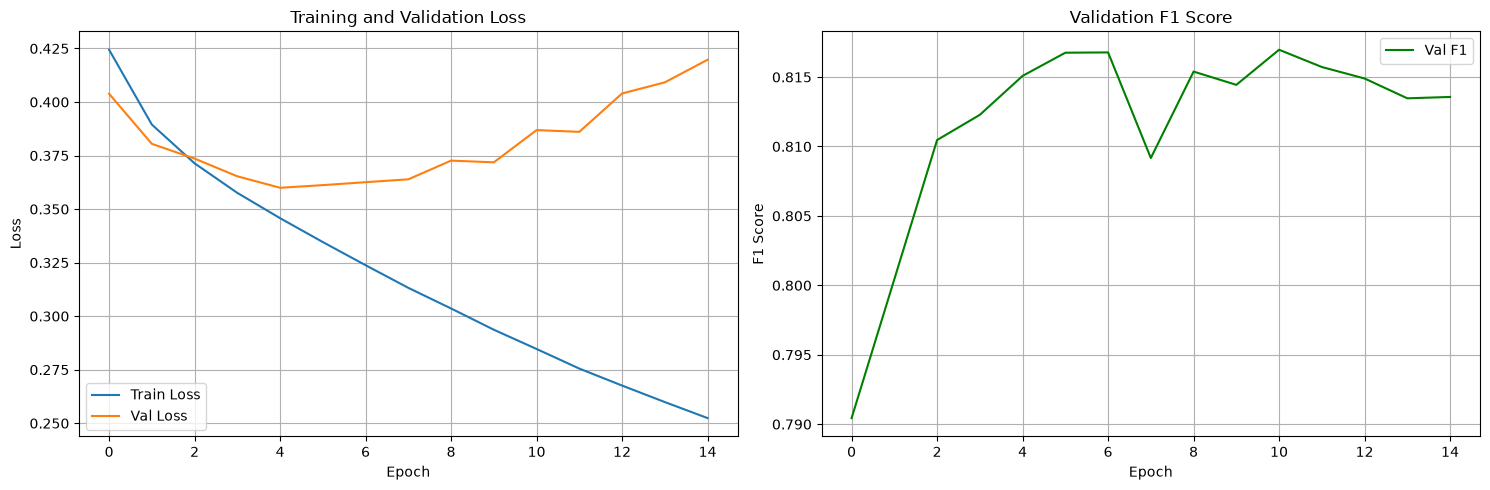

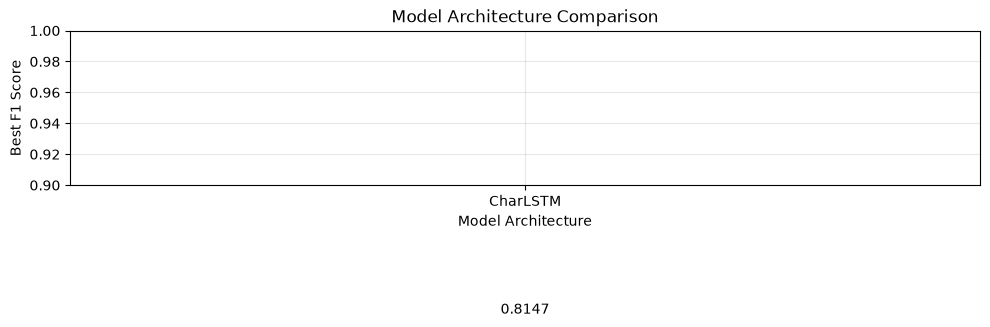

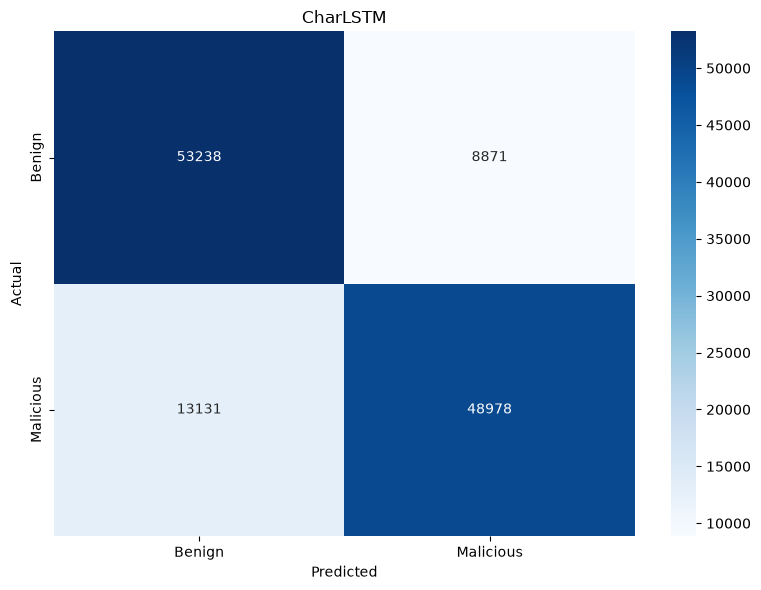


Confusion Matrix:
[[53238  8871]
 [13131 48978]]

True Negatives: 53238
False Positives: 8871
False Negatives: 13131
True Positives: 48978

Adjusting threshold for 0.001 FPR...


In [26]:

# Plot training history
def plot_training_history(history):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Loss
    axes[0].plot(history['train_loss'], label='Train Loss')
    axes[0].plot(history['val_loss'], label='Val Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss')
    axes[0].legend()
    axes[0].grid(True)

    # F1 Score
    axes[1].plot(history['val_f1'], label='Val F1', color='green')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('F1 Score')
    axes[1].set_title('Validation F1 Score')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_training_history(history)

# Compare all models
def plot_model_comparison(studies):
    model_names = list(studies.keys())
    f1_scores = [studies[name].best_trial.value for name in model_names]

    plt.figure(figsize=(10, 6))
    bars = plt.bar(model_names, f1_scores, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
    plt.xlabel('Model Architecture')
    plt.ylabel('Best F1 Score')
    plt.title('Model Architecture Comparison')
    plt.ylim([0.9, 1.0])

    # Add value labels on bars
    for bar, score in zip(bars, f1_scores):
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{score:.4f}', ha='center', va='bottom')

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_model_comparison(studies)

# Confusion Matrix
def plot_confusion_matrix(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in test_loader:
            inputs = batch['input'].to(device)
            labels = batch['label'].to(device)

            outputs = model(inputs).squeeze()
            probs = torch.sigmoid(outputs)
            preds = (probs > 0.5).float()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    cm = confusion_matrix(all_labels, all_preds)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign', 'Malicious'],
                yticklabels=['Benign', 'Malicious'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('CharLSTM')
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

    return cm

test_loader = DataLoader(test_dataset, batch_size=64)
cm = plot_confusion_matrix(best_model, test_loader, device)

print("\nConfusion Matrix:")
print(cm)
print(f"\nTrue Negatives: {cm[0,0]}")
print(f"False Positives: {cm[0,1]}")
print(f"False Negatives: {cm[1,0]}")
print(f"True Positives: {cm[1,1]}")

# Calculate FPR at different thresholds (for 0.001 FPR target)
fpr_target = 0.001
print(f"\nAdjusting threshold for {fpr_target} FPR...")

In [20]:
# Data Augmentation for Domains
def augment_domain(domain, augmentation_type='typo'):
    """
    Simple data augmentation for domain names
    """
    if augmentation_type == 'typo':
        # Random character substitution
        domain_list = list(domain)
        if len(domain_list) > 0:
            idx = np.random.randint(0, len(domain_list))
            domain_list[idx] = chr(np.random.randint(97, 123))  # Random lowercase letter
        return ''.join(domain_list)
    elif augmentation_type == 'insertion':
        # Random character insertion
        domain_list = list(domain)
        idx = np.random.randint(0, len(domain_list)+1)
        domain_list.insert(idx, chr(np.random.randint(97, 123)))
        return ''.join(domain_list)
    elif augmentation_type == 'deletion':
        # Random character deletion
        if len(domain) > 1:
            domain_list = list(domain)
            idx = np.random.randint(0, len(domain_list))
            del domain_list[idx]
            return ''.join(domain_list)
    return domain

# Ensemble Prediction
class EnsembleModel:
    """
    Ensemble of multiple trained models for improved robustness
    """
    def __init__(self, models):
        self.models = models

    def predict(self, dataloader, device):
        all_probs = []

        for model in self.models:
            model.eval()
            model_probs = []

            with torch.no_grad():
                for batch in dataloader:
                    inputs = batch['input'].to(device)
                    outputs = model(inputs).squeeze()
                    probs = torch.sigmoid(outputs)
                    model_probs.extend(probs.cpu().numpy())

            all_probs.append(model_probs)

        # Average predictions
        ensemble_probs = np.mean(all_probs, axis=0)
        return ensemble_probs

print("\n" + "="*60)
print("MODEL TRAINING COMPLETE!")
print("="*60)
print(f"\nBest Model: {best_model_type}")
print(f"Test Accuracy: {test_metrics['accuracy']:.4f}")
print(f"Test F1 Score: {test_metrics['f1']:.4f}")
print(f"Test AUC-ROC: {test_metrics['auc']:.4f}")
print("\nModel saved as: final_{}_model.pt".format(best_model_type))
print("Training history plot saved as: training_history.png")
print("Model comparison plot saved as: model_comparison.png")
print("Confusion matrix plot saved as: confusion_matrix.png")


MODEL TRAINING COMPLETE!

Best Model: CharLSTM
Test Accuracy: 0.8229
Test F1 Score: 0.8166
Test AUC-ROC: 0.9103

Model saved as: final_CharLSTM_model.pt
Training history plot saved as: training_history.png
Model comparison plot saved as: model_comparison.png
Confusion matrix plot saved as: confusion_matrix.png


In [12]:
# Create results summary
results_summary = {
    'best_model': best_model_type,
    'test_metrics': test_metrics,
    'hyperparameters': studies[best_model_type].best_trial.params,
    'all_models_performance': {
        model: studies[model].best_trial.value
        for model in studies.keys()
    }
}

# Save to file
import json
with open('results_summary.json', 'w') as f:
    json.dump(results_summary, f, indent=4)

print("\nResults summary saved to: results_summary.json")

NameError: name 'best_model_type' is not defined

In [20]:
# ==========================================
# CharLSTM: load final model and evaluate
# ==========================================

import json
import torch
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1) Recreate dataset exactly as before (Majestic + Hagezi already in domain_dataset.csv)
df = pd.read_csv("domain_dataset.csv")  # you already saved this in the notebook[file:16]

# Rebuild 80/10/10 split with same random_state and stratification as before[file:16]
train_df, test_val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)
val_df, test_df = train_test_split(
    test_val_df,
    test_size=0.5,
    random_state=42,
    stratify=test_val_df["label"]
)

print(f"Train size: {len(train_df)}, Val size: {len(val_df)}, Test size: {len(test_df)}")

# 2) Character tokenizer and Dataset (copied from the notebook, simplified)
class CharacterTokenizer:
    def __init__(self, max_length=32):
        self.max_length = max_length
        self.vocab_size = 128  # ASCII

    def encode(self, domain):
        domain = str(domain).lower()
        encoded = [ord(c) if ord(c) < 128 else 0 for c in domain]
        if len(encoded) <= self.max_length:
            encoded = [0] * (self.max_length - len(encoded)) + encoded
        else:
            encoded = encoded[-self.max_length:]
        return encoded

class DomainDataset(Dataset):
    def __init__(self, domains, labels, tokenizer):
        self.domains = list(domains)
        self.labels = list(labels)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.domains)

    def __getitem__(self, idx):
        domain = self.domains[idx]
        label = self.labels[idx]
        encoded = self.tokenizer.encode(domain)
        return {
            "input": torch.tensor(encoded, dtype=torch.long),
            "label": torch.tensor(label, dtype=torch.float32),
        }

tokenizer = CharacterTokenizer(max_length=32)

train_dataset = DomainDataset(train_df["domain"], train_df["label"], tokenizer)
val_dataset = DomainDataset(val_df["domain"], val_df["label"], tokenizer)
test_dataset = DomainDataset(test_df["domain"], test_df["label"], tokenizer)

BATCH_SIZE = 32
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# 3) CharLSTM architecture (copied from notebook, with dynamic fc sizing)
class CharLSTM(nn.Module):
    def __init__(self, vocab_size=128, embedding_dim=128, hidden_dim=256,
                 max_length=32, dropout_rate=0.5):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout_rate)

        with torch.no_grad():
            tmp = torch.zeros(1, max_length, dtype=torch.long)
            tmp = self.embedding(tmp)
            _, (hidden, _) = self.lstm(tmp)
            out_size = hidden[-1].shape[1]

        self.fc = nn.Linear(out_size, 1)

    def forward(self, x):
        x = self.embedding(x)
        _, (hidden, _) = self.lstm(x)
        x = hidden[-1]
        x = self.dropout(x)
        x = self.fc(x).squeeze(-1)
        return x

# Best hyperparameters from Optuna study
embedding_dim = 64
hidden_dim = 256
dropout_rate = 0.3910487002586611
max_length = 64
vocab_size = 128

model = CharLSTM(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    max_length=max_length,
    dropout_rate=dropout_rate,
).to(device)

model_memory = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
) / (1024 ** 2)
print(f"Model memory at rest: {model_memory}")

# 4) Load trained weights ONLY (no training)
state = torch.load("final_CharLSTM_model.pt", map_location=device)
model.load_state_dict(state)
model.eval()

# 5) Evaluate on test split
all_labels, all_probs = [], []

# Reset PyTorch's peak-memory tracker
torch.cuda.reset_peak_memory_stats()

with torch.no_grad():
    for batch in test_loader:
        inputs = batch["input"].to(device)
        labels = batch["label"].cpu().numpy()
        logits = model(inputs)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_labels.append(labels)
        all_probs.append(probs)

# Measure peak GPU memory used during inference
peak_allocated = torch.cuda.max_memory_allocated() / (1024 ** 2)
peak_reserved = torch.cuda.max_memory_reserved() / (1024 ** 2)

print(f"Peak allocated GPU memory: {peak_allocated:.2f} MiB")
print(f"Peak reserved GPU memory:  {peak_reserved:.2f} MiB")

all_labels = np.concatenate(all_labels)
all_probs = np.concatenate(all_probs)
all_preds = (all_probs >= 0.5).astype(int)

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, zero_division=0)
rec = recall_score(all_labels, all_preds, zero_division=0)
f1 = f1_score(all_labels, all_preds, zero_division=0)
try:
    auc = roc_auc_score(all_labels, all_probs)
except ValueError:
    auc = float("nan")
cm = confusion_matrix(all_labels, all_preds)

metrics_charlstm = {
    "model": "CharLSTM",
    "accuracy": float(acc),
    "precision": float(prec),
    "recall": float(rec),
    "f1": float(f1),
    "roc_auc": float(auc),
    "confusion_matrix": cm.tolist(),
    "num_test_samples": int(len(test_dataset)),
}

print(json.dumps(metrics_charlstm, indent=2))

# Save or update results_summary.json
try:
    with open("results_summary.json", "r") as f:
        summary = json.load(f)
except (FileNotFoundError, json.JSONDecodeError):
    summary = {}

summary["CharLSTM_final_test"] = metrics_charlstm

with open("results_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nSaved CharLSTM metrics to results_summary.json")


Train size: 993739, Val size: 124217, Test size: 124218
Model memory at rest: 1.2900428771972656
Peak allocated GPU memory: 166.94 MiB
Peak reserved GPU memory:  182.00 MiB
{
  "model": "CharLSTM",
  "accuracy": 0.8220789257595518,
  "precision": 0.8453729281767955,
  "recall": 0.7883559548535639,
  "f1": 0.8158694982046005,
  "roc_auc": 0.9099537251017992,
  "confusion_matrix": [
    [
      53153,
      8956
    ],
    [
      13145,
      48964
    ]
  ],
  "num_test_samples": 124218
}

Saved CharLSTM metrics to results_summary.json


0.9231637337006044
[0.5        0.50000403 0.50000805 ... 1.         1.         1.        ]
PR-AUC: 0.9232
Total predictions: 124218
Unique probabilities: 105821


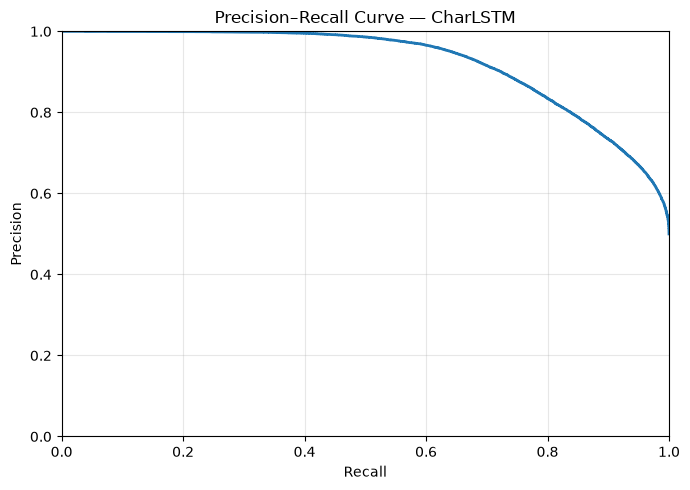

In [21]:
from sklearn.metrics import precision_recall_curve, average_precision_score, auc
import matplotlib.pyplot as plt
precision, recall, thresholds = precision_recall_curve(
    all_labels, all_probs
)

average_precision = average_precision_score(all_labels, all_probs)
print(average_precision)
print(precision)

pr_auc = auc(recall, precision)
print(f"PR-AUC: {pr_auc:.4f}")

print("Total predictions:", len(all_probs))
print("Unique probabilities:", len(np.unique(all_probs)))

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision,
    linewidth=2
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — CharLSTM")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('charlstm_pr_curve.png', dpi=1200, bbox_inches='tight')
plt.show()

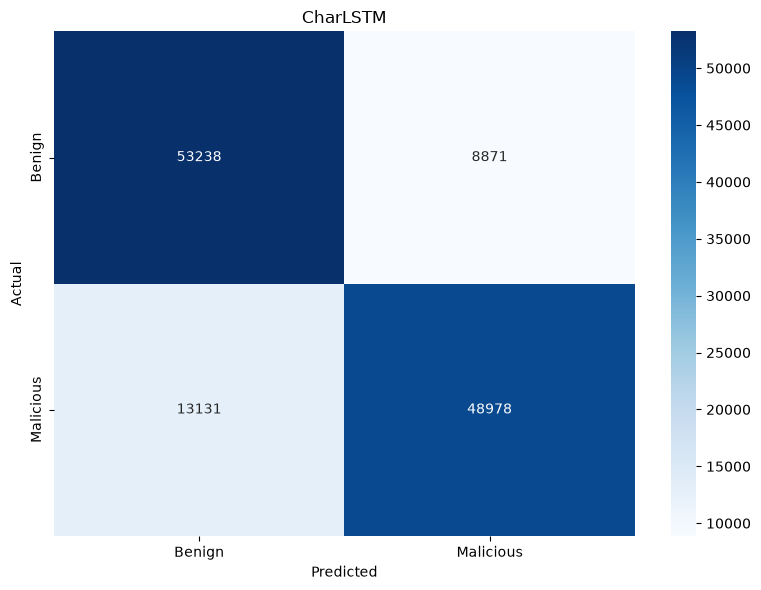

[[53238, 8871], [13131, 48978]]

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
def plot_confusion_matrix(cm):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign', 'Malicious'],
                yticklabels=['Benign', 'Malicious'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('CharLSTM')
    plt.tight_layout()
    plt.savefig('charlstm_confusion_matrix.png', dpi=1200, bbox_inches='tight')
    plt.show()

    return cm

plot_confusion_matrix([
    [
      53238,
      8871
    ],
    [
      13131,
      48978
    ]
  ])